
# **TASK 4: Sentiment Analysis**

In [1]:
!pip -q install vaderSentiment

In [2]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (10, 5)

In [3]:
from pathlib import Path

DATA_PATH = "/content/youtubeDataset.csv"

if not Path(DATA_PATH).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload youtubeDataset.csv.")
        DATA_PATH = csv_files[0]
    except ImportError:
        DATA_PATH = "youtubeDataset.csv"

print("Dataset path:", DATA_PATH)
print("File exists:", Path(DATA_PATH).exists())

Saving youtubeDataset.csv to youtubeDataset.csv
Dataset path: youtubeDataset.csv
File exists: True


In [4]:
required_columns = ["CommentText", "VideoTitle", "Likes", "Replies", "PublishedAt", "CountryCode", "CategoryID"]

try:
    df = pd.read_csv(DATA_PATH, encoding="utf-8", usecols=lambda c: c in required_columns, low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="latin1", usecols=lambda c: c in required_columns, low_memory=False)

print("Rows loaded:", f"{len(df):,}")
print("Columns loaded:", df.columns.tolist())
display(df.head())
display(pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}))

Rows loaded: 1,032,225
Columns loaded: ['VideoTitle', 'CommentText', 'Likes', 'Replies', 'PublishedAt', 'CountryCode', 'CategoryID']


,VideoTitle,CommentText,Likes,Replies,PublishedAt,CountryCode,CategoryID
0,They killed my friend.#tales #movie #shorts,Anyone know what movie this is?,0,2,1/15/2025 0:54,NZ,1
1,Man Utd conceding first penalty at home in years and this is their reaction ð­,The fact they're holding each other back while equally being most aggressive ðð,0,0,1/13/2025 23:51,AU,17
2,Welcome to Javascript Course,waiting next video will be?,1,0,7/6/2020 13:18,IN,27
3,Building web applications in Java with Spring Boot 3 â Tutorial,Thanks for the great video.\n\nI don't understand why the DB continues to be accesible through port 8080 when the lo...,0,1,9/18/2024 12:04,US,27
4,After a new engine her car dies on her way home makes me think the worst! ð±#fyp #mobile #love #help,Good person helping good people.\nThis is how it is in America with the exception of NY and DC.,3,1,1/10/2025 19:39,US,2


,missing_values,missing_percent
VideoTitle,0,0.0
CommentText,0,0.0
Likes,0,0.0
Replies,0,0.0
PublishedAt,0,0.0
CountryCode,0,0.0
CategoryID,0,0.0


In [5]:
# Set to None to analyze every non-empty comment. Default is 100,000 for a practical Colab run.
MAX_COMMENTS = None

df["CommentText"] = df["CommentText"].fillna("").astype(str).str.strip()
df = df[df["CommentText"].ne("")].copy()
df = df.drop_duplicates().reset_index(drop=True)

# Convert numeric fields and dates safely
for col in ["Likes", "Replies", "CategoryID"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "PublishedAt" in df.columns:
    df["PublishedAt"] = pd.to_datetime(df["PublishedAt"], errors="coerce")

rows_available = len(df)
if MAX_COMMENTS is not None and rows_available > MAX_COMMENTS:
    # fixed random_state makes the sample reproducible
    df = df.sample(n=MAX_COMMENTS, random_state=42).reset_index(drop=True)

print(f"Non-empty comments available: {rows_available:,}")
print(f"Comments selected for sentiment analysis: {len(df):,}")
print("Sample is reproducible: random_state=42")

Non-empty comments available: 1,030,940
Comments selected for sentiment analysis: 1,030,940
Sample is reproducible: random_state=42


In [6]:
analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    scores = analyzer.polarity_scores(str(text))
    compound = scores["compound"]
    if compound >= 0.05:
        label = "Positive"
    elif compound <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    return pd.Series({
        "sentiment": label,
        "compound": compound,
        "positive_score": scores["pos"],
        "neutral_score": scores["neu"],
        "negative_score": scores["neg"]
    })

sentiment_results = df["CommentText"].apply(analyze_sentiment)
df = pd.concat([df, sentiment_results], axis=1)

display(df[["CommentText", "sentiment", "compound"]].head(10))
print("Sentiment analysis complete.")

,CommentText,sentiment,compound
0,Anyone know what movie this is?,Neutral,0.0000
1,The fact they're holding each other back while equally being most aggressive ðð,Negative,-0.2247
2,waiting next video will be?,Neutral,0.0000
3,Thanks for the great video.\n\nI don't understand why the DB continues to be accesible through port 8080 when the lo...,Positive,0.6662
4,Good person helping good people.\nThis is how it is in America with the exception of NY and DC.,Positive,0.7906
5,Dei lÃ¸k de seimð,Neutral,0.0000
6,Number two because it looks the best with it,Positive,0.6705
7,Thank God we donât have to listen to his drivel anymore,Positive,0.5574
8,Very similar thing happened to me! We lived near a beach that had a stray dog. We would all leave food out for her. ...,Positive,0.4071
9,im about to cryð¢,Neutral,0.0000


Sentiment analysis complete.


,comment_count,percentage
sentiment,,
Positive,463342,44.94
Neutral,335945,32.59
Negative,231653,22.47


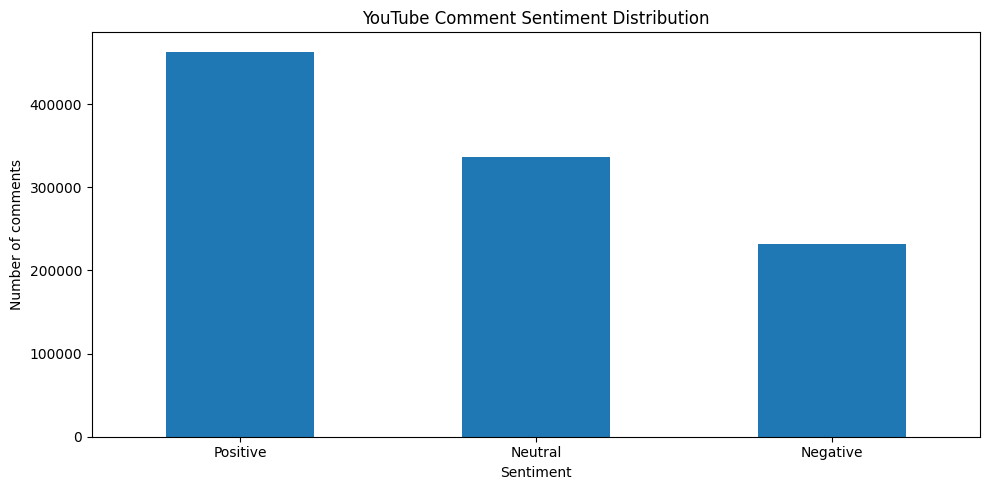

In [7]:
sentiment_counts = df["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"], fill_value=0)
sentiment_percent = (sentiment_counts / len(df) * 100).round(2)

sentiment_summary = pd.DataFrame({
    "comment_count": sentiment_counts,
    "percentage": sentiment_percent
})
display(sentiment_summary)

ax = sentiment_counts.plot(kind="bar", rot=0)
ax.set_title("YouTube Comment Sentiment Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of comments")
plt.tight_layout()
plt.show()

,matched_comments
emotion,
joy / appreciation,179989
anger / frustration,26442
sadness,19245
surprise,13726
fear / worry,9544


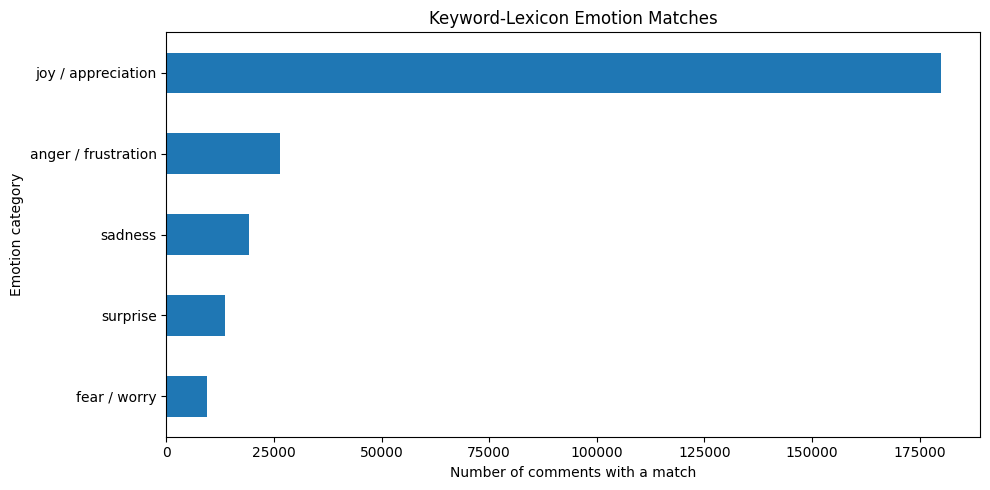

In [8]:
emotion_lexicon = {
    "joy / appreciation": ["love", "great", "amazing", "awesome", "excellent", "beautiful", "thank you", "thanks", "happy", "wonderful", "perfect", "best"],
    "anger / frustration": ["hate", "angry", "annoying", "terrible", "worst", "stupid", "disappointed", "boring", "waste", "ridiculous"],
    "sadness": ["sad", "sorry", "miss you", "heartbreaking", "cry", "unfortunately", "depressed", "painful"],
    "surprise": ["wow", "unexpected", "surprised", "shocking", "no way", "incredible"],
    "fear / worry": ["afraid", "scared", "worried", "danger", "fear", "nervous", "concerned"]
}

def detect_emotions(text):
    t = str(text).lower()
    found = []
    for emotion, terms in emotion_lexicon.items():
        if any(term in t for term in terms):
            found.append(emotion)
    return ", ".join(found) if found else "No lexicon match"

df["emotion_tags"] = df["CommentText"].apply(detect_emotions)
emotion_counts = (
    df.assign(emotion=df["emotion_tags"].str.split(", "))
      .explode("emotion")
      .query("emotion != 'No lexicon match'")["emotion"]
      .value_counts()
)
display(emotion_counts.rename("matched_comments").to_frame())

if not emotion_counts.empty:
    emotion_counts.sort_values().plot(kind="barh")
    plt.title("Keyword-Lexicon Emotion Matches")
    plt.xlabel("Number of comments with a match")
    plt.ylabel("Emotion category")
    plt.tight_layout()
    plt.show()
else:
    print("No emotion keywords matched in the analyzed comments.")

,VideoTitle,comments,positive_pct,neutral_pct,negative_pct,average_compound,total_likes,total_replies
0,Whale Vomit Is Worth Millions ð³,1191,25.02,50.04,24.94,0.00,178791,668
1,A man saved a mountain lion and raise it with love,1174,48.98,35.86,15.16,0.27,31025,766
2,After a new engine her car dies on her way home makes me think the worst! ð±#fyp #mobile #love #help,1151,53.87,24.67,21.46,0.23,75519,886
3,Others wall running vs this man (Credit to Storror),1090,18.90,62.11,18.99,-0.00,222009,990
4,Trump: 'All hell will break out' if hostages aren't returned,1003,31.41,36.49,32.10,-0.03,34527,1383
5,Trapped in a Vacuum (@lawrencemalstaf - on IG) #shorts,1000,17.70,42.30,40.00,-0.12,19284,178
6,From Trash to Treasure ðð¸ (@cinema_chelsey on TikTok) #shorts,970,31.55,32.68,35.77,-0.03,51801,404
7,California inferno rages out-of-control as arson investigation launched | BBC News,933,30.33,33.76,35.91,-0.05,27352,2009
8,LIFT THE TOP CHALLENGE #shorts,924,49.46,33.01,17.53,0.21,54549,571
9,Nopales is what my future kids will eat as a midnight snack. #cactus #nopales #food,918,41.61,35.51,22.88,0.12,137602,248


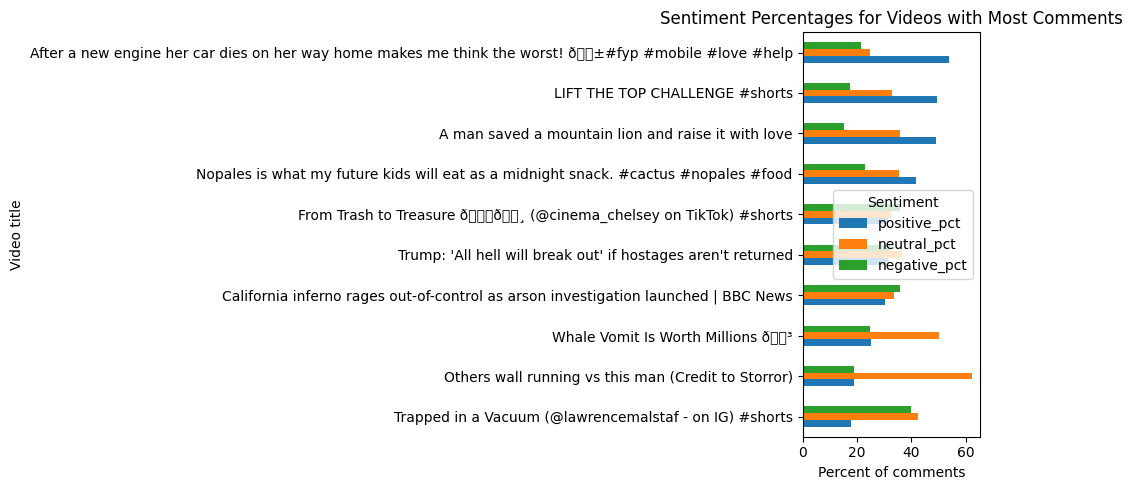

In [9]:
if "VideoTitle" in df.columns:
    video_summary = (
        df.groupby("VideoTitle", dropna=False)
          .agg(
              comments=("sentiment", "size"),
              positive_pct=("sentiment", lambda s: (s == "Positive").mean() * 100),
              neutral_pct=("sentiment", lambda s: (s == "Neutral").mean() * 100),
              negative_pct=("sentiment", lambda s: (s == "Negative").mean() * 100),
              average_compound=("compound", "mean"),
              total_likes=("Likes", "sum"),
              total_replies=("Replies", "sum")
          )
          .query("comments >= 100")
          .sort_values("comments", ascending=False)
          .reset_index()
    )
    display(video_summary.head(15).round(2))

    if not video_summary.empty:
        top_videos = video_summary.head(10).sort_values("positive_pct")
        top_videos.plot(x="VideoTitle", y=["positive_pct", "neutral_pct", "negative_pct"], kind="barh")
        plt.title("Sentiment Percentages for Videos with Most Comments")
        plt.xlabel("Percent of comments")
        plt.ylabel("Video title")
        plt.legend(title="Sentiment")
        plt.tight_layout()
        plt.show()

,CountryCode,comments,positive_pct,negative_pct,average_compound
0,US,320984,48.08,24.56,0.16
1,AU,140983,42.59,22.94,0.13
2,GB,130218,38.98,26.00,0.09
3,IN,120921,55.58,8.25,0.29
4,CA,117748,44.79,23.48,0.15
5,IE,73811,37.86,24.94,0.09
6,NZ,71569,35.96,24.66,0.07
7,DE,37602,52.95,25.61,0.18
8,PH,17104,27.26,19.32,0.06


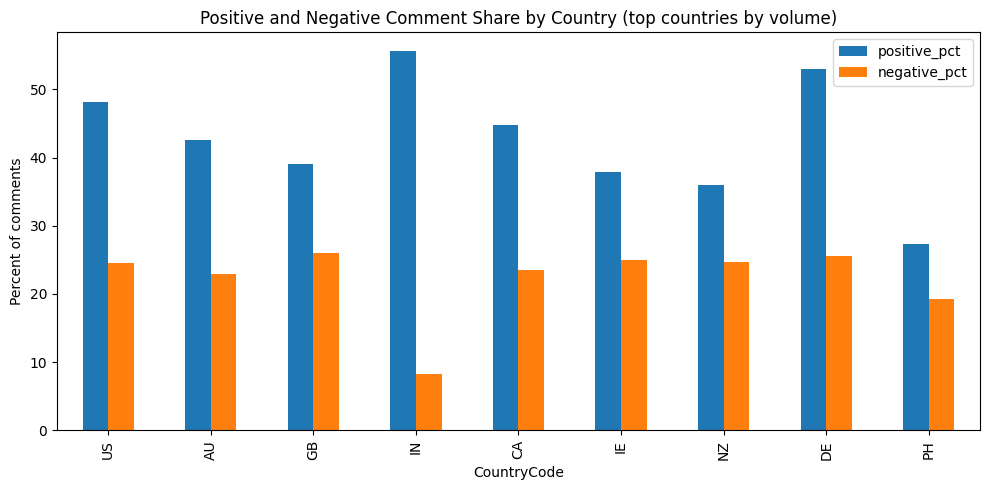

,month,comments,positive_pct,negative_pct,average_compound
119,2023-03,4243,61.58,13.83,0.32
120,2023-04,3687,56.88,16.90,0.26
121,2023-05,4374,58.64,15.78,0.27
122,2023-06,3913,57.45,15.74,0.27
123,2023-07,4300,57.84,14.00,0.28
124,2023-08,4275,58.62,13.64,0.29
125,2023-09,4369,59.72,12.61,0.31
126,2023-10,4454,60.51,11.79,0.32
127,2023-11,3878,59.64,12.69,0.30
128,2023-12,4250,57.51,13.46,0.28


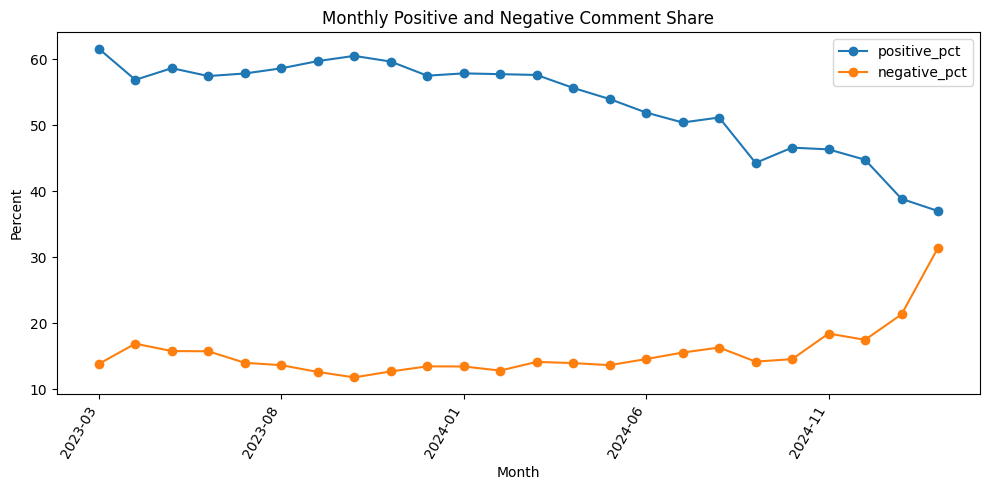

In [10]:
if "CountryCode" in df.columns:
    country_summary = (
        df.dropna(subset=["CountryCode"])
          .groupby("CountryCode")
          .agg(
              comments=("sentiment", "size"),
              positive_pct=("sentiment", lambda s: (s == "Positive").mean() * 100),
              negative_pct=("sentiment", lambda s: (s == "Negative").mean() * 100),
              average_compound=("compound", "mean")
          )
          .query("comments >= 100")
          .sort_values("comments", ascending=False)
          .head(15)
          .reset_index()
    )
    display(country_summary.round(2))

    if not country_summary.empty:
        country_summary.set_index("CountryCode")[["positive_pct", "negative_pct"]].plot(kind="bar")
        plt.title("Positive and Negative Comment Share by Country (top countries by volume)")
        plt.ylabel("Percent of comments")
        plt.tight_layout()
        plt.show()

if "PublishedAt" in df.columns:
    dated = df.dropna(subset=["PublishedAt"]).copy()
    if not dated.empty:
        dated["month"] = dated["PublishedAt"].dt.to_period("M").astype(str)
        monthly = dated.groupby("month").agg(
            comments=("sentiment", "size"),
            positive_pct=("sentiment", lambda s: (s == "Positive").mean() * 100),
            negative_pct=("sentiment", lambda s: (s == "Negative").mean() * 100),
            average_compound=("compound", "mean")
        ).reset_index()
        display(monthly.tail(24).round(2))
        monthly.tail(24).plot(x="month", y=["positive_pct", "negative_pct"], marker="o")
        plt.title("Monthly Positive and Negative Comment Share")
        plt.xlabel("Month")
        plt.ylabel("Percent")
        plt.xticks(rotation=60, ha="right")
        plt.tight_layout()
        plt.show()

In [11]:
print("Examples classified as Positive:")
display(df.loc[df["sentiment"] == "Positive", ["CommentText", "compound", "Likes", "Replies"]].head(5))

print("Examples classified as Negative:")
display(df.loc[df["sentiment"] == "Negative", ["CommentText", "compound", "Likes", "Replies"]].head(5))

print("Examples classified as Neutral:")
display(df.loc[df["sentiment"] == "Neutral", ["CommentText", "compound", "Likes", "Replies"]].head(5))

if "Likes" in df.columns:
    engagement = df.groupby("sentiment").agg(
        comments=("sentiment", "size"),
        median_likes=("Likes", "median"),
        mean_likes=("Likes", "mean")
    ).round(2)
    if "Replies" in df.columns:
        engagement["median_replies"] = df.groupby("sentiment")["Replies"].median()
        engagement["mean_replies"] = df.groupby("sentiment")["Replies"].mean().round(2)
    display(engagement)

Examples classified as Positive:


,CommentText,compound,Likes,Replies
3,Thanks for the great video.\n\nI don't understand why the DB continues to be accesible through port 8080 when the lo...,0.6662,0,1
4,Good person helping good people.\nThis is how it is in America with the exception of NY and DC.,0.7906,3,1
6,Number two because it looks the best with it,0.6705,0,0
7,Thank God we donât have to listen to his drivel anymore,0.5574,0,0
8,Very similar thing happened to me! We lived near a beach that had a stray dog. We would all leave food out for her. ...,0.4071,0,0


Examples classified as Negative:


,CommentText,compound,Likes,Replies
1,The fact they're holding each other back while equally being most aggressive ðð,-0.2247,0,0
23,It hurt wen u crossed by a niga u loveð¢,-0.5267,0,0
24,"356k people now know Elon is a liar. Always has been, good move dipsh*t.",-0.1027,1,0
30,When is CNN stopping calling themselves a NEWS network?,-0.1531,0,0
32,"Suspended means temporary, the decided to leave indefinitely... Not hard to understand",-0.4596,0,0


Examples classified as Neutral:


,CommentText,compound,Likes,Replies
0,Anyone know what movie this is?,0.0,0,2
2,waiting next video will be?,0.0,1,0
5,Dei lÃ¸k de seimð,0.0,0,0
9,im about to cryð¢,0.0,0,0
11,Big deal.,0.0,0,0


,comments,median_likes,mean_likes,median_replies,mean_replies
sentiment,,,,,
Negative,231653,0.0,122.49,0.0,2.90
Neutral,335945,0.0,77.88,0.0,1.35
Positive,463342,0.0,108.77,0.0,2.08


In [12]:
output_dir = "task4_outputs"
os.makedirs(output_dir, exist_ok=True)

df.to_csv(os.path.join(output_dir, "youtube_comments_sentiment.csv"), index=False, encoding="utf-8-sig")
sentiment_summary.to_csv(os.path.join(output_dir, "sentiment_summary.csv"))

if "VideoTitle" in df.columns and "video_summary" in globals():
    video_summary.to_csv(os.path.join(output_dir, "sentiment_by_video.csv"), index=False)
if "country_summary" in globals():
    country_summary.to_csv(os.path.join(output_dir, "sentiment_by_country.csv"), index=False)
if "monthly" in globals():
    monthly.to_csv(os.path.join(output_dir, "monthly_sentiment_trends.csv"), index=False)

print("Saved files:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

Saved files:
- monthly_sentiment_trends.csv
- sentiment_by_country.csv
- sentiment_by_video.csv
- sentiment_summary.csv
- youtube_comments_sentiment.csv


In [13]:
from google.colab import files

files.download("task4_outputs/youtube_comments_sentiment.csv")
files.download("task4_outputs/sentiment_summary.csv")
files.download("task4_outputs/sentiment_by_video.csv")
files.download("task4_outputs/sentiment_by_country.csv")
files.download("task4_outputs/monthly_sentiment_trends.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>